## 1. Setup & Locate Dataset

In [2]:
import os, hashlib, random, collections, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

INPUT = Path("/kaggle/input")
yaml_files = list(INPUT.rglob("data.yaml"))
print("Found data.yaml files:", yaml_files)

ROOT = None
for p in yaml_files:
    if "signlanguageenglish" in str(p):
        ROOT = p.parent
        break
if ROOT is None and yaml_files:
    ROOT = yaml_files[0].parent
assert ROOT is not None, "data.yaml not found - is the dataset added to this notebook?"
print("DATASET ROOT:", ROOT)

Found data.yaml files: [PosixPath('/kaggle/input/datasets/fenetefera/signlanguageenglish/data.yaml')]
DATASET ROOT: /kaggle/input/datasets/fenetefera/signlanguageenglish


## 2. Folder Structure, data.yaml & READMEs

In [3]:
print("Top-level contents:")
for p in sorted(ROOT.iterdir()):
    print("  ", "DIR " if p.is_dir() else "FILE", p.name)

print("\nExpected split folders:")
for split in ["train", "valid", "test"]:
    for sub in ["images", "labels"]:
        d = ROOT / split / sub
        print(f"  {split}/{sub}:", "OK" if d.exists() else "missing")

print("\n--- data.yaml ---")
print((ROOT / "data.yaml").read_text())

for readme in ["README.dataset.txt", "README.roboflow.txt"]:
    f = ROOT / readme
    if f.exists():
        print(f"\n--- {readme} (first 1500 chars) ---")
        print(f.read_text()[:1500])

Top-level contents:
   FILE README.dataset.txt
   FILE README.roboflow.txt
   FILE data.yaml
   DIR  test
   DIR  train

Expected split folders:
  train/images: OK
  train/labels: OK
  valid/images: missing
  valid/labels: missing
  test/images: OK
  test/labels: OK

--- data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 18
names: ['I', 'apple', 'can', 'get', 'good', 'have', 'help', 'how', 'like', 'love', 'my', 'no', 'sorry', 'thank-you', 'want', 'yes', 'you', 'your']

roboflow:
  workspace: asl-dataset
  project: asl-dataset-p9yw8
  version: 1
  license: Public Domain
  url: https://universe.roboflow.com/asl-dataset/asl-dataset-p9yw8/dataset/1

--- README.dataset.txt (first 1500 chars) ---
# ASL Dataset > v1 preprocessed
https://universe.roboflow.com/asl-dataset/asl-dataset-p9yw8

Provided by a Roboflow user
License: Public Domain

# Overview

The ASL Dataset is an object detection dataset of a few common ASL words w/ bounding boxes. It was curated as 

## 3. Images vs Labels per Split

In [4]:
cfg = yaml.safe_load(open(ROOT / "data.yaml"))
names = cfg["names"]
if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=int)]
NC = len(names)
print("Number of classes:", NC)
print(names)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = [s for s in ["train", "valid", "test"] if (ROOT / s / "images").exists()]

rows, data = [], {}
for s in SPLITS:
    imgs = sorted(p for p in (ROOT / s / "images").iterdir() if p.suffix.lower() in IMG_EXT)
    lbls = sorted((ROOT / s / "labels").glob("*.txt"))
    img_stems = {p.stem for p in imgs}
    lbl_stems = {p.stem for p in lbls}
    empty = [p for p in lbls if p.stat().st_size == 0]
    rows.append(dict(
        split=s,
        images=len(imgs),
        labels=len(lbls),
        images_without_label=len(img_stems - lbl_stems),
        labels_without_image=len(lbl_stems - img_stems),
        empty_label_files=len(empty),
    ))
    data[s] = dict(imgs=imgs, lbls=lbls)

summary = pd.DataFrame(rows)
display(summary)

Number of classes: 18
['I', 'apple', 'can', 'get', 'good', 'have', 'help', 'how', 'like', 'love', 'my', 'no', 'sorry', 'thank-you', 'want', 'yes', 'you', 'your']


,split,images,labels,images_without_label,labels_without_image,empty_label_files
0,train,197,197,0,0,0
1,test,26,26,0,0,0


## 4. Parse All Label Files

In [5]:
records, bad_lines = [], []
for s in SPLITS:
    for lp in data[s]["lbls"]:
        for i, line in enumerate(lp.read_text().splitlines()):
            parts = line.split()
            if not parts:
                continue
            try:
                cls = int(float(parts[0]))
                vals = list(map(float, parts[1:]))
            except ValueError:
                bad_lines.append((s, lp.name, i, "non-numeric"))
                continue
            if len(vals) == 4:
                cx, cy, w, h = vals
            elif len(vals) >= 6 and len(vals) % 2 == 0:  # polygon (segmentation) format
                xs, ys = vals[0::2], vals[1::2]
                cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
                w, h = max(xs) - min(xs), max(ys) - min(ys)
                bad_lines.append((s, lp.name, i, "polygon format (not plain boxes)"))
            else:
                bad_lines.append((s, lp.name, i, f"unexpected {len(vals)} values"))
                continue
            records.append(dict(split=s, file=lp.stem, cls=cls, cx=cx, cy=cy, w=w, h=h))

df = pd.DataFrame(records)
df["name"] = df["cls"].map(lambda c: names[c] if 0 <= c < NC else f"INVALID_{c}")
print("Total boxes parsed:", len(df))
print("Malformed / polygon lines:", len(bad_lines))
print(bad_lines[:10])
display(df.head())

Total boxes parsed: 223
Malformed / polygon lines: 0
[]


,split,file,cls,cx,cy,w,h,name
0,train,Apple1_png.rf.56d6b1ea7b9b0163b49b7aafa4480469,1,0.405273,0.386719,0.108398,0.114258,apple
1,train,I10_JPG.rf.a185a9a4afd4007bdca5aced0dea631a,0,0.403320,0.627930,0.134766,0.115234,I
2,train,I11_JPG.rf.c778b35fdf498222880a88adaf84fa84,0,0.651367,0.597656,0.166016,0.107422,I
3,train,I12_JPG.rf.42b68b1d449c70608780e74ac560454f,0,0.573242,0.574219,0.115234,0.139648,I
4,train,I13_JPG.rf.225086fe71ff191de35c73767e897b09,0,0.426758,0.531250,0.108398,0.097656,I


## 5. Class Distribution

split,test,train,total
name,,,
I,0,17,17
thank-you,4,12,16
like,2,13,15
good,3,12,15
help,2,12,14
want,3,10,13
how,1,12,13
apple,2,10,12
can,3,9,12


Classes with no boxes in any split: []


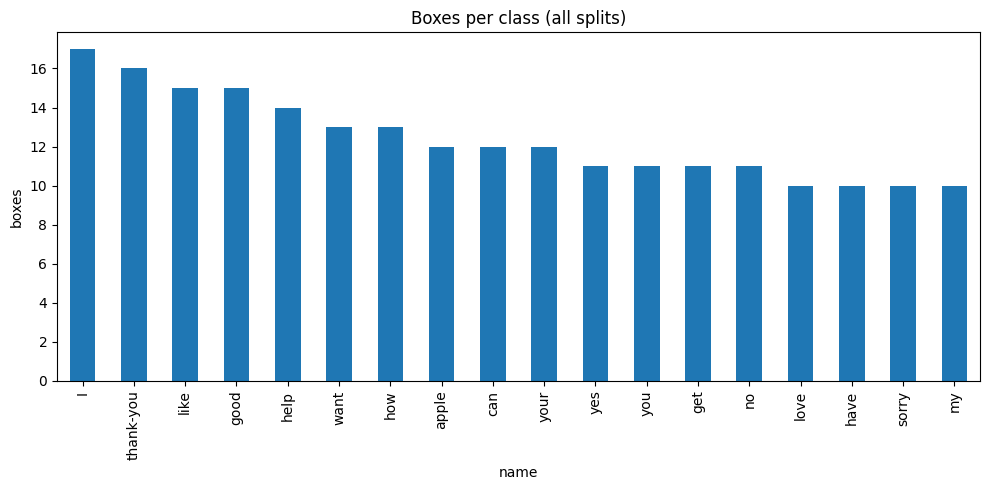

Train boxes per class -> min: 9, median: 10.0, max: 17


In [6]:
counts = df.pivot_table(index="name", columns="split", values="cls", aggfunc="count", fill_value=0)
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
display(counts)

no_boxes_at_all = [n for n in names if n not in counts.index]
print("Classes with no boxes in any split:", no_boxes_at_all)

fig, ax = plt.subplots(figsize=(max(10, NC * 0.35), 5))
counts["total"].plot.bar(ax=ax)
ax.set_title("Boxes per class (all splits)")
ax.set_ylabel("boxes")
plt.tight_layout()
plt.show()

if "train" in counts:
    t = counts["train"]
    print(f"Train boxes per class -> min: {t.min()}, median: {t.median()}, max: {t.max()}")

## 6. Bounding Box Statistics

                w           h        area
count  223.000000  223.000000  223.000000
mean     0.237843    0.171258    0.043339
std      0.159972    0.068571    0.036147
min      0.072266    0.064453    0.005623
25%      0.131836    0.121582    0.016829
50%      0.188477    0.158203    0.032358
75%      0.279785    0.208496    0.060785
max      0.917969    0.427734    0.229317

Boxes per image:
count    223.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64

Out-of-range boxes: 0
Invalid class ids: 0
Very tiny boxes (<0.5% of image): 0


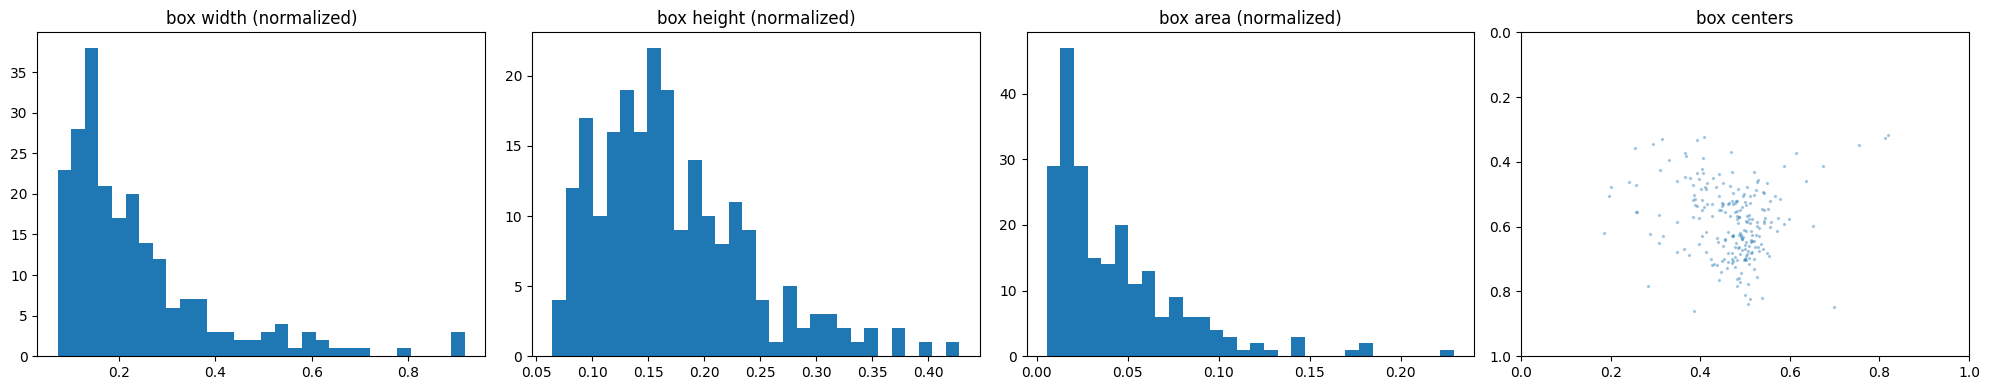

In [7]:
df["area"] = df["w"] * df["h"]
print(df[["w", "h", "area"]].describe())

boxes_per_img = df.groupby(["split", "file"]).size()
print("\nBoxes per image:")
print(boxes_per_img.describe())

coord_cols = ["cx", "cy", "w", "h"]
out_of_range = df[(df[coord_cols] < 0).any(axis=1) | (df[coord_cols] > 1).any(axis=1)]
invalid_cls = df[df["name"].str.startswith("INVALID")]
tiny = df[df["area"] < 0.005]
print("\nOut-of-range boxes:", len(out_of_range))
print("Invalid class ids:", len(invalid_cls))
print("Very tiny boxes (<0.5% of image):", len(tiny))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(df["w"], bins=30); axes[0].set_title("box width (normalized)")
axes[1].hist(df["h"], bins=30); axes[1].set_title("box height (normalized)")
axes[2].hist(df["area"], bins=30); axes[2].set_title("box area (normalized)")
axes[3].scatter(df["cx"], df["cy"], s=2, alpha=0.3); axes[3].set_title("box centers")
axes[3].set_xlim(0, 1); axes[3].set_ylim(1, 0)
plt.tight_layout()
plt.show()

## 7. Image Integrity & Sizes

In [8]:
size_counter = collections.Counter()
corrupt = []
for s in SPLITS:
    for p in data[s]["imgs"]:
        try:
            with Image.open(p) as im:
                size_counter[im.size] += 1
                im.verify()
        except Exception as e:
            corrupt.append((s, p.name, str(e)[:80]))

print("Image sizes (W, H): count")
for k, v in size_counter.most_common(10):
    print("  ", k, v)
print("Corrupt / unreadable images:", len(corrupt))
print(corrupt[:5])

Image sizes (W, H): count
   (1024, 1024) 223
Corrupt / unreadable images: 0
[]


## 8. Train/Test Leakage Check

In [9]:
def md5_of(p):
    return hashlib.md5(p.read_bytes()).hexdigest()

def src_id(p):
    # Roboflow names files "<original>.rf.<hash>.jpg"; augmented copies share the part before ".rf."
    return p.name.split(".rf.")[0]

hashes = {s: [md5_of(p) for p in data[s]["imgs"]] for s in SPLITS}
srcs = {s: [src_id(p) for p in data[s]["imgs"]] for s in SPLITS}
has_rf = any(".rf." in p.name for s in SPLITS for p in data[s]["imgs"][:50])

print("Exact duplicate images inside each split:")
for s in SPLITS:
    print(f"  {s}: {len(hashes[s]) - len(set(hashes[s]))}")

leak_exact, leak_src = {}, {}
print("\nOverlap between splits:")
for a, b in itertools.combinations(SPLITS, 2):
    leak_exact[(a, b)] = len(set(hashes[a]) & set(hashes[b]))
    print(f"  {a} vs {b}: exact duplicates = {leak_exact[(a, b)]}", end="")
    if has_rf:
        leak_src[(a, b)] = len(set(srcs[a]) & set(srcs[b]))
        print(f" | same Roboflow source image = {leak_src[(a, b)]}")
    else:
        print()

Exact duplicate images inside each split:
  train: 0
  test: 0

Overlap between splits:
  train vs test: exact duplicates = 0 | same Roboflow source image = 0


## 9. Sample Images with Boxes

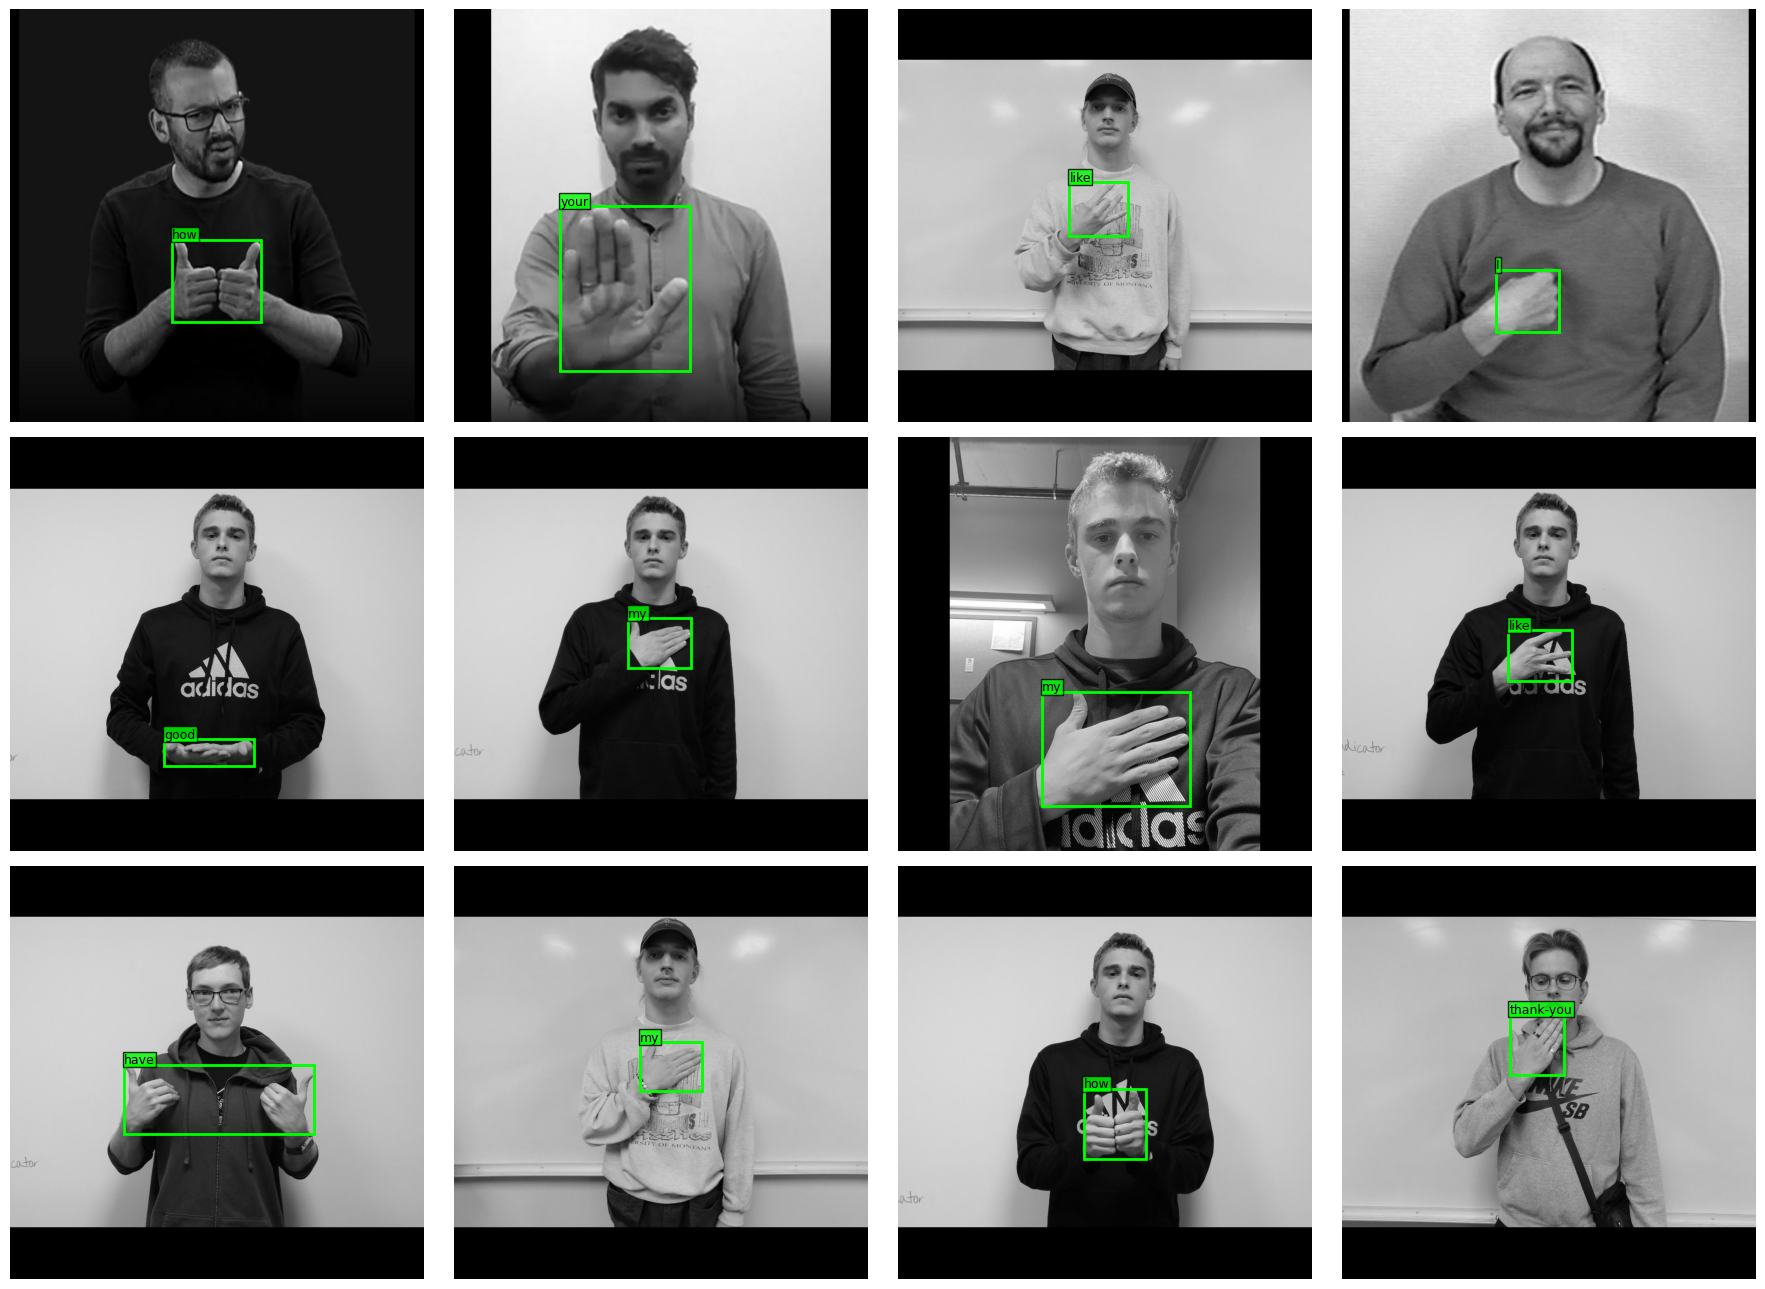

In [10]:
def draw(ax, img_path, split):
    img = Image.open(img_path).convert("RGB")
    W, H = img.size
    ax.imshow(img)
    lp = ROOT / split / "labels" / (img_path.stem + ".txt")
    if lp.exists():
        for line in lp.read_text().splitlines():
            p = line.split()
            if len(p) != 5:
                continue
            c = int(float(p[0]))
            cx, cy, w, h = map(float, p[1:])
            x, y = (cx - w / 2) * W, (cy - h / 2) * H
            ax.add_patch(patches.Rectangle((x, y), w * W, h * H, fill=False, linewidth=2, edgecolor="lime"))
            label = names[c] if 0 <= c < NC else str(c)
            ax.text(x, max(y - 4, 10), label, color="black", fontsize=9,
                    bbox=dict(facecolor="lime", alpha=0.8, pad=1))
    ax.axis("off")

random.seed(0)
sample = random.sample(data["train"]["imgs"], min(12, len(data["train"]["imgs"])))
fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, p in zip(axes.flat, sample):
    draw(ax, p, "train")
for ax in list(axes.flat)[len(sample):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 10. One Example per Class

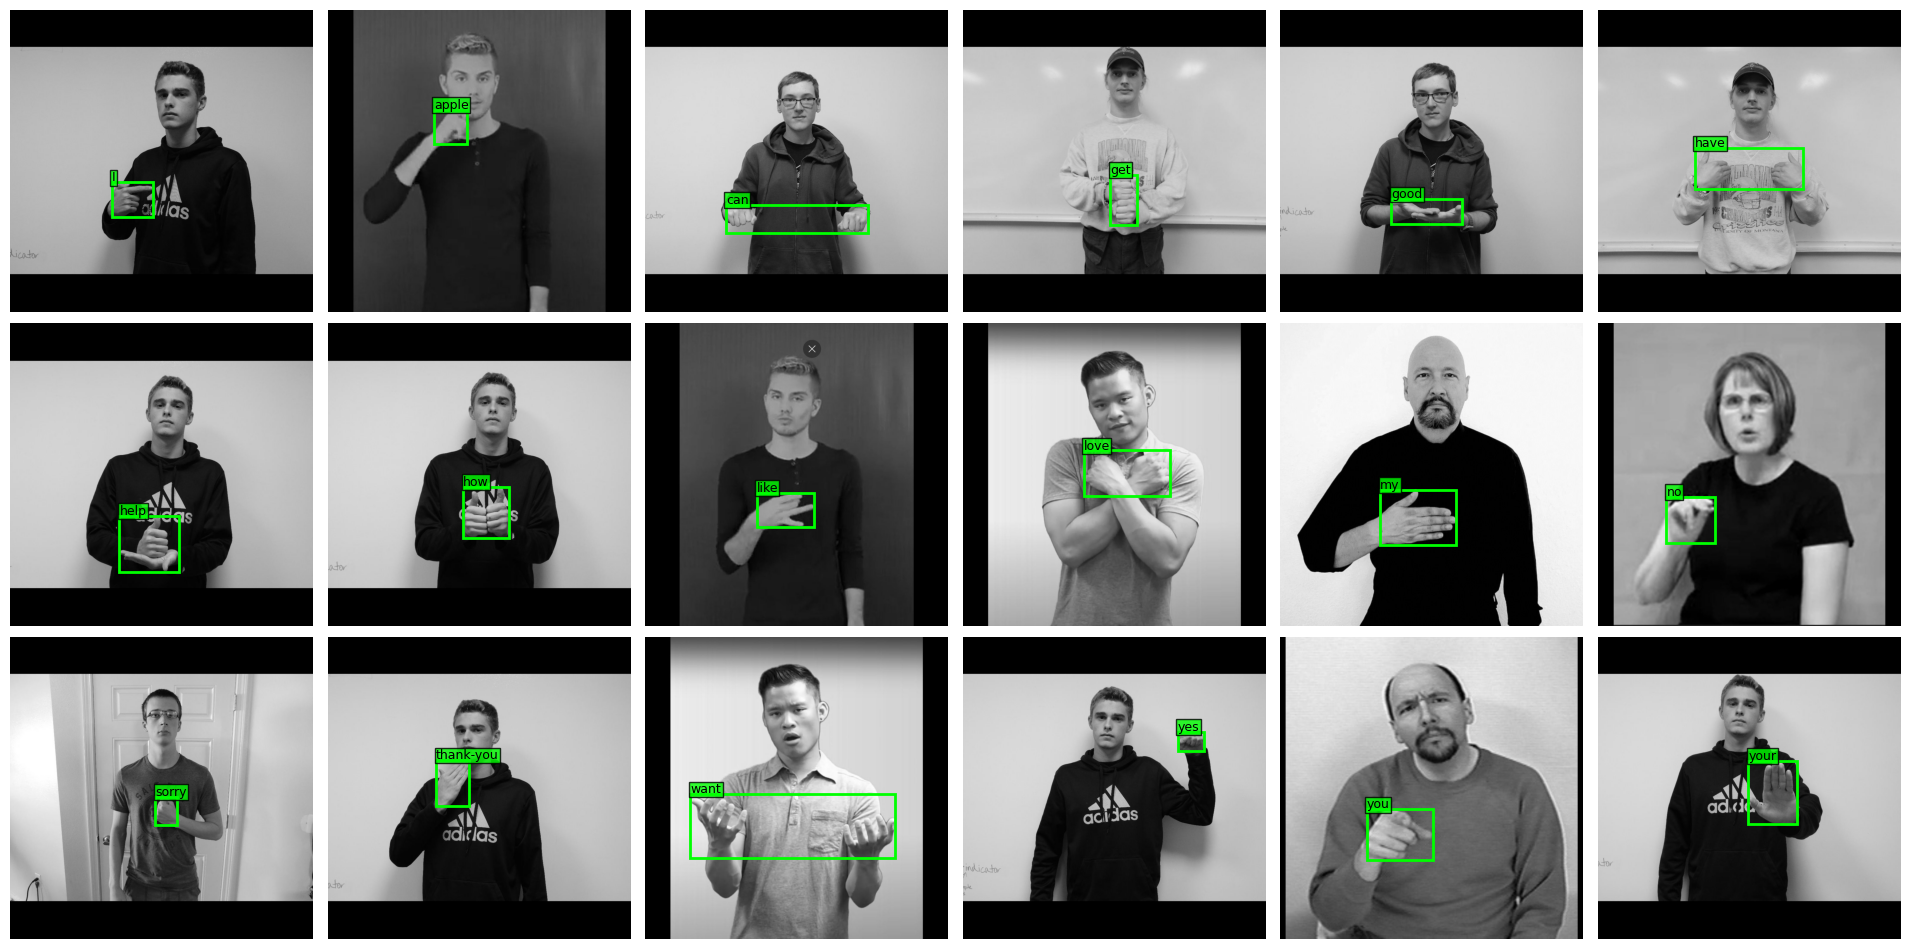

Showing first 18 of 18 classes


In [11]:
MAX_CLASSES = 24
shown = []
train_df = df[df["split"] == "train"]
for c in sorted(train_df["cls"].unique()):
    if c < 0 or c >= NC:
        continue
    fname = train_df[train_df["cls"] == c]["file"].iloc[0]
    matches = [p for p in data["train"]["imgs"] if p.stem == fname]
    if matches:
        shown.append(matches[0])
    if len(shown) >= MAX_CLASSES:
        break

cols = 6
rows_n = int(np.ceil(len(shown) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(3.2 * cols, 3.2 * rows_n))
axes = np.atleast_1d(axes).flatten()
for ax, p in zip(axes, shown):
    draw(ax, p, "train")
for ax in axes[len(shown):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Showing first {len(shown)} of {NC} classes")

## 11. Data Health Verdict

In [12]:
report = []
def add(level, msg):
    report.append((level, msg))

if "train" not in SPLITS:
    add("FAIL", "No train split found")
if "valid" not in SPLITS:
    add("WARN", "No valid split: use test as validation for the quick run (metrics will be slightly optimistic)")

for _, r in summary.iterrows():
    if r["images_without_label"]:
        add("WARN", f"{r['split']}: {r['images_without_label']} images have no label file")
    if r["labels_without_image"]:
        add("WARN", f"{r['split']}: {r['labels_without_image']} label files have no image")
    if r["empty_label_files"]:
        add("INFO", f"{r['split']}: {r['empty_label_files']} empty label files (treated as background images)")

if bad_lines:
    add("WARN", f"{len(bad_lines)} malformed or polygon-format label lines")
if len(invalid_cls):
    add("FAIL", f"{len(invalid_cls)} boxes use class ids outside 0..{NC - 1}")
if len(out_of_range):
    add("WARN", f"{len(out_of_range)} boxes have coordinates outside 0..1")
if corrupt:
    add("FAIL", f"{len(corrupt)} corrupt or unreadable images")
if len(size_counter) > 1:
    add("INFO", f"Multiple image sizes found: {dict(size_counter.most_common(3))}")

if "train" in counts:
    per_class = counts["train"].reindex(names).fillna(0)
else:
    per_class = pd.Series(0, index=names)
zero = [n for n, c in per_class.items() if c == 0]
low = [n for n, c in per_class.items() if 0 < c < 30]
if zero:
    add("FAIL", f"{len(zero)} classes have 0 train boxes: {zero[:10]}")
if low:
    add("WARN", f"{len(low)} classes have fewer than 30 train boxes: {low[:10]}")
nonzero = per_class[per_class > 0]
if len(nonzero) and nonzero.max() / nonzero.min() > 10:
    add("WARN", f"Class imbalance ratio is {nonzero.max() / nonzero.min():.1f}x (max/min train boxes)")

for k, v in leak_exact.items():
    if v:
        add("WARN", f"{v} exact duplicate images shared between {k[0]} and {k[1]}")
for k, v in leak_src.items():
    if v:
        add("WARN", f"{v} Roboflow source images appear in both {k[0]} and {k[1]} (augmented leakage)")

print(f"Classes: {NC} | train images: {len(data['train']['imgs']) if 'train' in data else 0} | total boxes: {len(df)}")
if len(nonzero):
    print(f"Train boxes per class: min {int(nonzero.min())}, median {int(nonzero.median())}, max {int(nonzero.max())}")
print()
for level, msg in report:
    print(f"[{level}] {msg}")
if not report:
    print("[OK] No issues found")

fails = [m for l, m in report if l == "FAIL"]
warns = [m for l, m in report if l == "WARN"]
print()
if fails:
    print("VERDICT: NOT READY - fix the FAIL items above before training")
elif warns:
    print("VERDICT: READY WITH WARNINGS - review the WARN items, then train")
else:
    print("VERDICT: READY TO TRAIN")

Classes: 18 | train images: 197 | total boxes: 223
Train boxes per class: min 9, median 10, max 17

[WARN] No valid split: use test as validation for the quick run (metrics will be slightly optimistic)
[WARN] 18 classes have fewer than 30 train boxes: ['I', 'apple', 'can', 'get', 'good', 'have', 'help', 'how', 'like', 'love']

VERDICT: READY WITH WARNINGS - review the WARN items, then train


### install ultralytics

In [14]:
!pip install -q ultralytics

## 12. Config & Locate Dataset

In [15]:
import os, shutil, json, random, collections
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import torch

# ---------------- CONFIG ----------------
SEED = 42
VAL_FRACTION = 0.2   # per-class share moved to validation (min 1 image per class)
EPOCHS = 120         # tiny dataset -> each epoch is only ~12 steps, so we need many epochs
PATIENCE = 40
IMGSZ = 640
BATCH = 16
# ----------------------------------------

random.seed(SEED)
np.random.seed(SEED)

yaml_files = list(Path("/kaggle/input").rglob("data.yaml"))
ROOT = next((p.parent for p in yaml_files if "signlanguageenglish" in str(p)), yaml_files[0].parent)

cfg = yaml.safe_load(open(ROOT / "data.yaml"))
names = cfg["names"]
if isinstance(names, dict):
    names = [names[k] for k in sorted(names, key=int)]
NC = len(names)

WORK = Path("/kaggle/working")
DATA = WORK / "asl_data"

print("Dataset root:", ROOT)
print(f"{NC} classes:", names)
print("GPU available:", torch.cuda.is_available())

Dataset root: /kaggle/input/datasets/fenetefera/signlanguageenglish
18 classes: ['I', 'apple', 'can', 'get', 'good', 'have', 'help', 'how', 'like', 'love', 'my', 'no', 'sorry', 'thank-you', 'want', 'yes', 'you', 'your']
GPU available: True


## 13. Build Stratified Train/Val Split

In [16]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Pool every labeled image from all splits (the dataset has no valid folder and test misses 6 classes)
items = []  # (image_path, label_path, class_id)
for split in ["train", "valid", "test"]:
    img_dir, lbl_dir = ROOT / split / "images", ROOT / split / "labels"
    if not img_dir.exists():
        continue
    for ip in sorted(img_dir.iterdir()):
        if ip.suffix.lower() not in IMG_EXT:
            continue
        lp = lbl_dir / (ip.stem + ".txt")
        if not lp.exists() or lp.stat().st_size == 0:
            continue
        cls_ids = [int(float(l.split()[0])) for l in lp.read_text().splitlines() if l.strip()]
        items.append((ip, lp, collections.Counter(cls_ids).most_common(1)[0][0]))
print("Usable labeled images:", len(items))

by_class = collections.defaultdict(list)
for it in items:
    by_class[it[2]].append(it)

train_items, val_items = [], []
for c, lst in sorted(by_class.items()):
    random.shuffle(lst)
    n_val = min(max(1, round(len(lst) * VAL_FRACTION)), len(lst) - 1)
    val_items += lst[:n_val]
    train_items += lst[n_val:]

if DATA.exists():
    shutil.rmtree(DATA)
for split, lst in [("train", train_items), ("val", val_items)]:
    (DATA / split / "images").mkdir(parents=True)
    (DATA / split / "labels").mkdir(parents=True)
    for ip, lp, c in lst:
        shutil.copy(ip, DATA / split / "images" / ip.name)
        shutil.copy(lp, DATA / split / "labels" / lp.name)

split_table = pd.DataFrame({
    "train": pd.Series(collections.Counter(names[c] for _, _, c in train_items)),
    "val": pd.Series(collections.Counter(names[c] for _, _, c in val_items)),
}).fillna(0).astype(int).reindex(names)
display(split_table)
print(f"train images: {len(train_items)} | val images: {len(val_items)}")

Usable labeled images: 223


,train,val
I,14,3
apple,10,2
can,10,2
get,9,2
good,12,3
have,8,2
help,11,3
how,10,3
like,12,3
love,8,2


train images: 180 | val images: 43


## 14. Write data.yaml

In [17]:
data_yaml = DATA / "data.yaml"
with open(data_yaml, "w") as f:
    yaml.safe_dump({
        "path": str(DATA),
        "train": str(DATA / "train" / "images"),
        "val": str(DATA / "val" / "images"),
        "nc": NC,
        "names": names,
    }, f, sort_keys=False)
print(data_yaml.read_text())

path: /kaggle/working/asl_data
train: /kaggle/working/asl_data/train/images
val: /kaggle/working/asl_data/val/images
nc: 18
names:
- I
- apple
- can
- get
- good
- have
- help
- how
- like
- love
- my
- 'no'
- sorry
- thank-you
- want
- 'yes'
- you
- your



## 15. Train YOLOv8n

In [18]:
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO("yolov8n.pt")

results = model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMGSZ,
    batch=BATCH,
    device=device,
    workers=2,
    project=str(WORK / "runs"),
    name="asl_word",
    exist_ok=True,
    seed=SEED,
    cache=True,
    # light extra augmentation because the dataset is tiny (no augmentation was applied at export)
    degrees=10.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    close_mosaic=15,
    plots=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/asl_data/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=120, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/120      2.57G      1.646      5.351      1.672          4        640: 100% ━━━━━━━━━━━━ 12/12 11.0it/s 1.1s.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 9.4it/s 0.2s0.4s
                   all         43         43          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/120      2.57G      1.537      4.774      1.518          9        640: 100% ━━━━━━━━━━━━ 12/12 11.1it/s 1.1s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s3.1s
                   all         43         43          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/120      2.57G        1.5      4.471      1.532          6        640: 100% ━━━━━━━━━━━━ 12/12 10.4it/s 1.2s.1s
                 Class     Images  Instances 

## 16. Validation Metrics & Training Curves

Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,158 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1585.4±342.0 MB/s, size: 43.1 KB)
val: Scanning /kaggle/working/asl_data/val/labels.cache... 43 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43/43 20.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 6.8it/s 0.4s0.3s
                   all         43         43      0.734      0.852      0.938      0.764
                     I          3          3      0.456      0.667      0.555      0.289
                 apple          2          2      0.711          1      0.995      0.821
                   can          2          2      0.581        0.5      0.828      0.596
                   get          2          2       0.75          1      0.995      0.646
                  good          3          

,class,AP50,AP50-95
0,I,0.555000,0.288667
1,you,0.745000,0.670500
2,can,0.828333,0.596333
3,want,0.830000,0.636583
4,good,0.995000,0.862500
5,have,0.995000,0.920250
6,help,0.995000,0.896000
7,apple,0.995000,0.820750
8,how,0.995000,0.740833
9,like,0.995000,0.812750


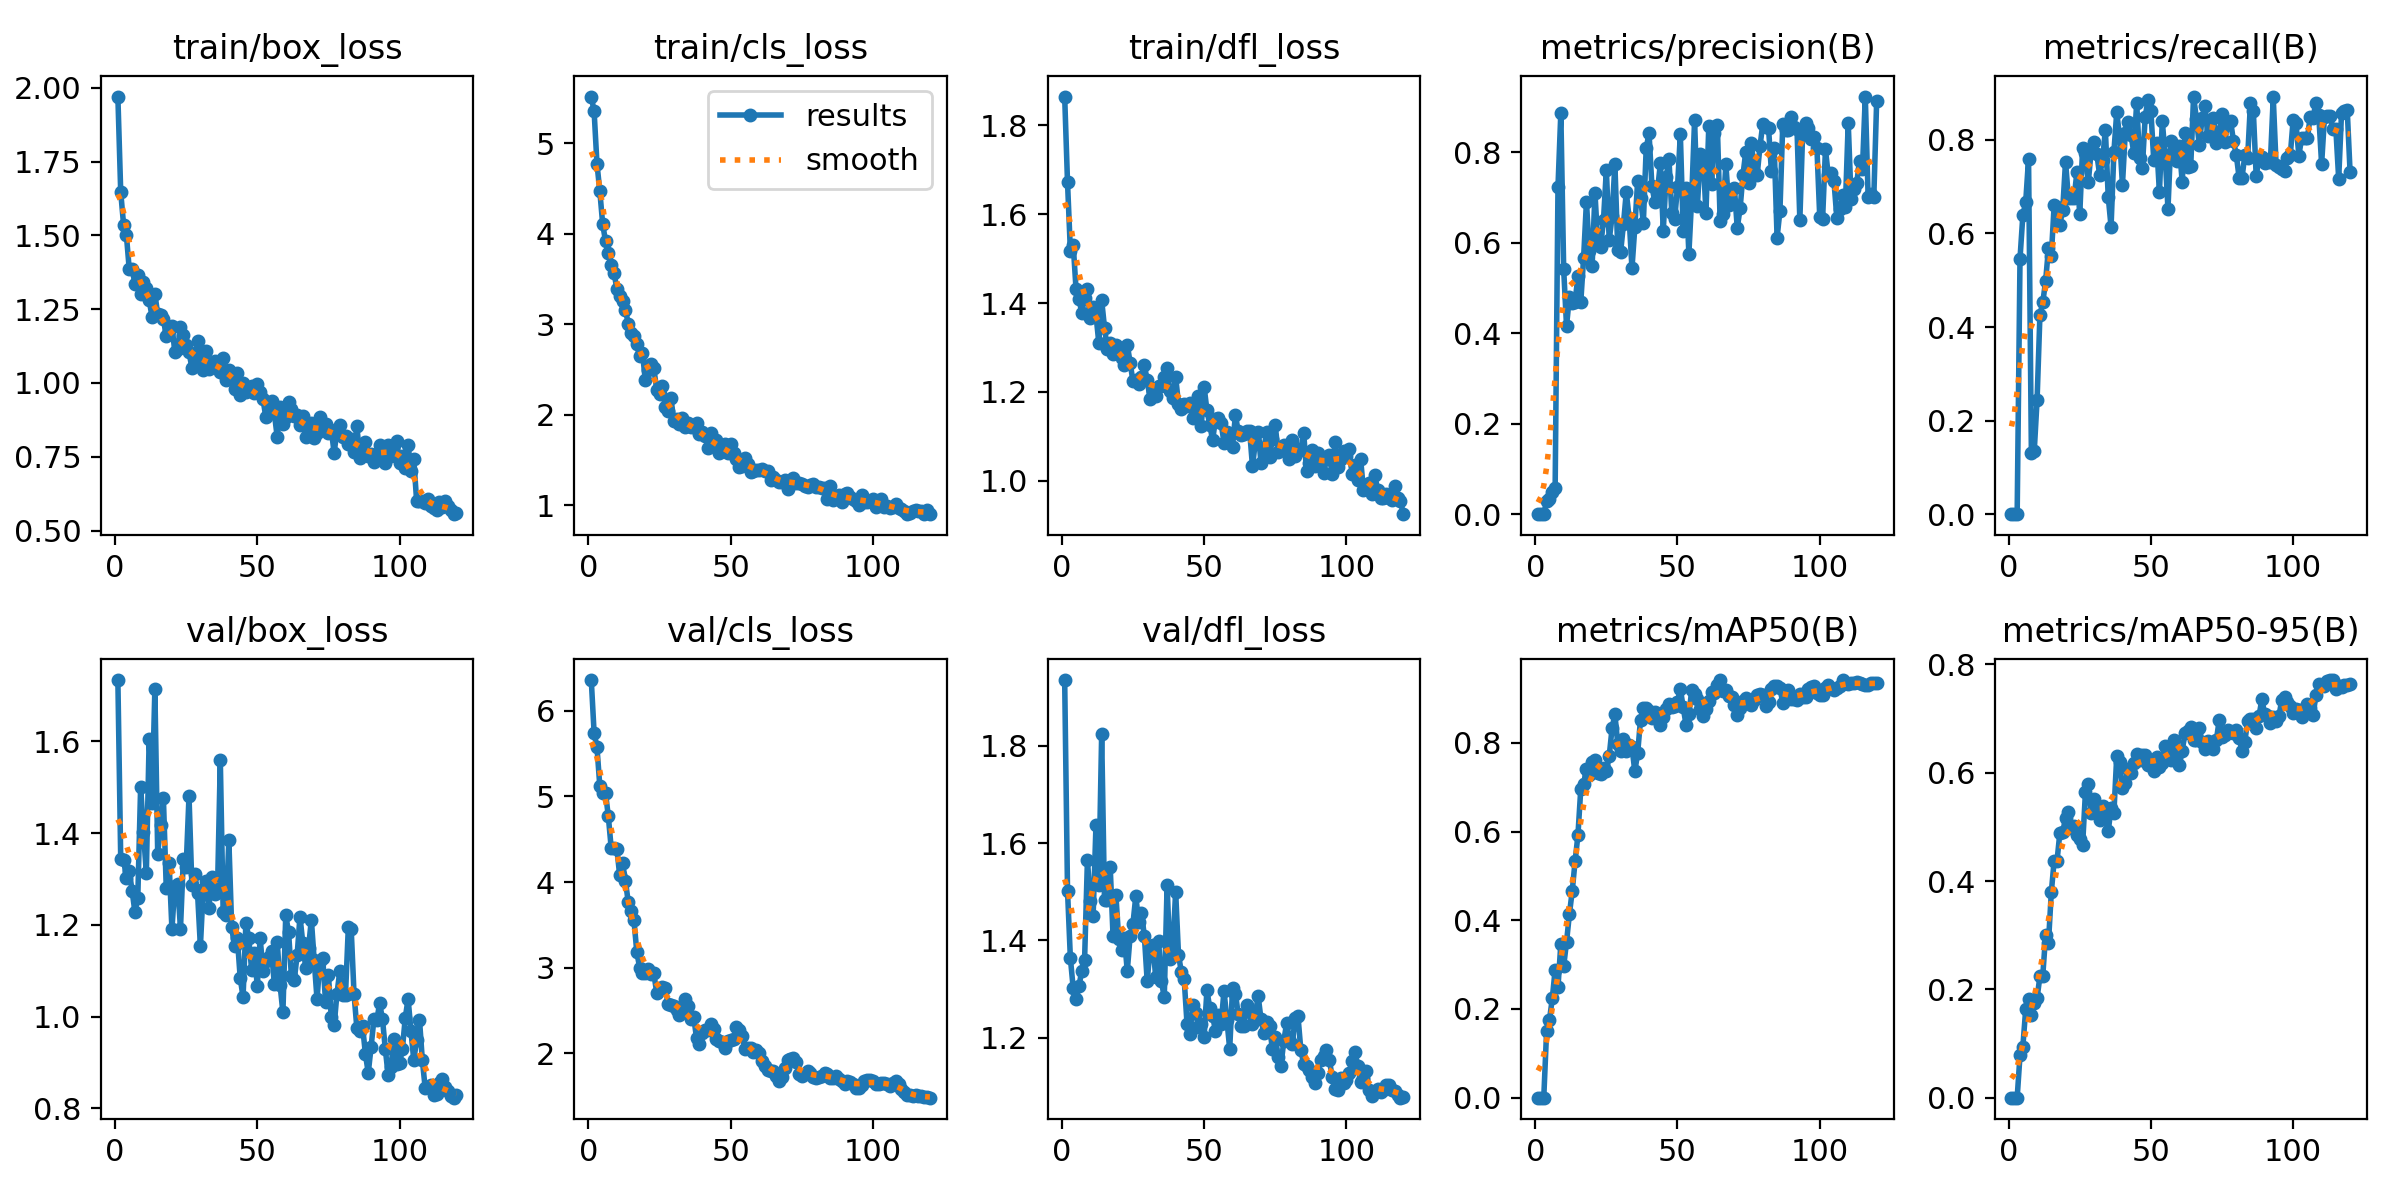

In [19]:
from IPython.display import Image as IPImage

best_path = WORK / "runs" / "asl_word" / "weights" / "best.pt"
best = YOLO(str(best_path))
m = best.val(data=str(data_yaml), imgsz=IMGSZ, device=device, plots=False)

print(f"mAP50: {m.box.map50:.3f} | mAP50-95: {m.box.map:.3f} | precision: {m.box.mp:.3f} | recall: {m.box.mr:.3f}")
per_class = pd.DataFrame({
    "class": [names[i] for i in m.box.ap_class_index],
    "AP50": m.box.ap50,
    "AP50-95": m.box.ap,
}).sort_values("AP50").reset_index(drop=True)
display(per_class)

display(IPImage(str(WORK / "runs" / "asl_word" / "results.png")))

## 17. Predictions on Validation Images

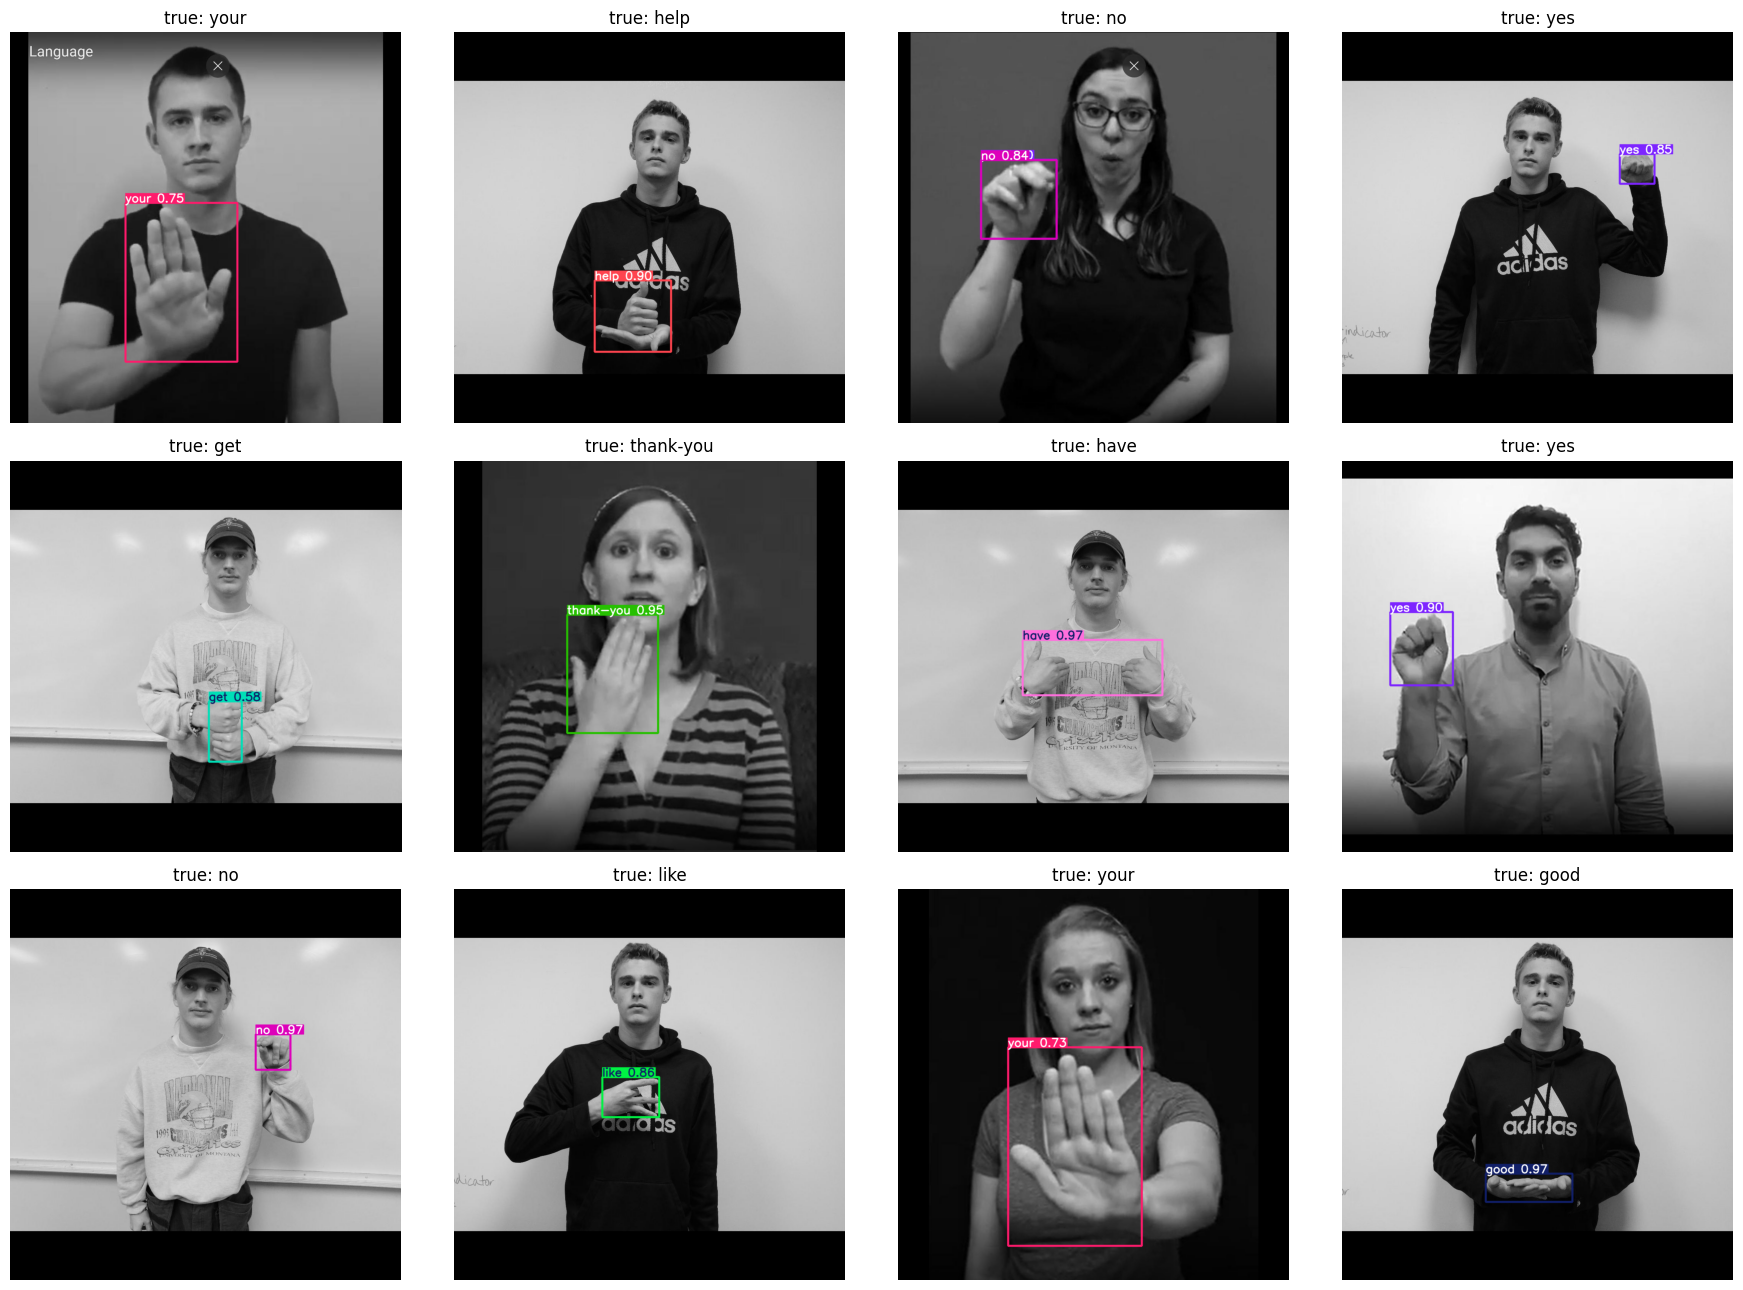

In [20]:
val_imgs = sorted((DATA / "val" / "images").iterdir())
sample = random.sample(val_imgs, min(12, len(val_imgs)))

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, p in zip(axes.flat, sample):
    r = best.predict(str(p), imgsz=IMGSZ, conf=0.25, device=device, verbose=False)[0]
    ax.imshow(r.plot()[:, :, ::-1])
    truth = names[int((DATA / "val" / "labels" / (p.stem + ".txt")).read_text().split()[0])]
    ax.set_title(f"true: {truth}")
    ax.axis("off")
for ax in list(axes.flat)[len(sample):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 18. Export & Package Files

In [21]:
OUT = WORK / "asl_model_package"
OUT.mkdir(exist_ok=True)

shutil.copy(best_path, OUT / "best.pt")
shutil.copy(best_path, WORK / "best.pt")
with open(OUT / "classes.json", "w") as f:
    json.dump(names, f, indent=2)

# Optional ONNX export for onnxruntime
try:
    onnx_path = best.export(format="onnx", imgsz=IMGSZ, simplify=True)
    shutil.copy(onnx_path, OUT / "best.onnx")
except Exception as e:
    print("ONNX export skipped:", e)

# Zip the model package and the split dataset (the local app can reuse it to avoid forgetting during live fine-tuning)
shutil.make_archive(str(WORK / "asl_model_package"), "zip", OUT)
shutil.make_archive(str(WORK / "asl_base_dataset"), "zip", DATA)
print(sorted(p.name for p in WORK.iterdir() if p.is_file()))

Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 3,009,158 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/kaggle/working/runs/asl_word/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 22, 8400) (6.0 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 345ms
Prepared 2 packages in 364ms
Installed 2 packages in 9ms
 + onnxruntime==1.30.0
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 2.8s, saved as

## 19. Download Links

In [22]:
from IPython.display import FileLink, display

os.chdir(WORK)
for name in ["best.pt", "asl_model_package.zip", "asl_base_dataset.zip"]:
    if (WORK / name).exists():
        display(FileLink(name))

/kaggle/working/best.pt

/kaggle/working/asl_model_package.zip

/kaggle/working/asl_base_dataset.zip